# 1. Load Datasets and Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns          
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix

### Load the combined dataset

In [2]:
df_wine = pd.read_csv(r"..\data\processed\wine_quality_combined.csv")

# 2. Target Creation & Feature Encoding

### Create binary target: 1 if quality >= 7 (high quality), 0 otherwise

In [11]:
df_wine['quality_label'] = (df_wine['quality'] >= 7).astype(int)

### Encode categorical variable 'type' (red/white) into numeric

In [4]:
df_wine['type_code'] = (df_wine['type'] == 'white').astype(int)

## Separate Features (X) and Target (y)
### Drop original 'quality', target 'quality_label', and string 'type' columns to avoid data leakage

In [5]:
X = df_wine.drop(columns=['quality', 'quality_label', 'type'])
y = df_wine['quality_label']

# 3. Train-Test Split (80% train, 20% test with stratification)

In [6]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=17, stratify=y)

# 4. Feature Scaling (Essential for Logistic Regression)

In [7]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 5. Model Training
### Using class_weight='balanced' to handle target class imbalance

In [8]:
log_reg = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)
log_reg.fit(X_train_scaled, y_train)

,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to u

# 6. Model Evaluation

In [9]:
y_pred = log_reg.predict(X_test_scaled)
y_pred_proba = log_reg.predict_proba(X_test_scaled)[:, 1]

print("=== Confusion Matrix ===")
print(confusion_matrix(y_test, y_pred))

print("\n=== Classification Report ===")
print(classification_report(y_test, y_pred))

print(f"ROC-AUC Score: {roc_auc_score(y_test, y_pred_proba):.4f}")

=== Confusion Matrix ===
[[738 306]
 [ 53 203]]

=== Classification Report ===
              precision    recall  f1-score   support

           0       0.93      0.71      0.80      1044
           1       0.40      0.79      0.53       256

    accuracy                           0.72      1300
   macro avg       0.67      0.75      0.67      1300
weighted avg       0.83      0.72      0.75      1300

ROC-AUC Score: 0.8230


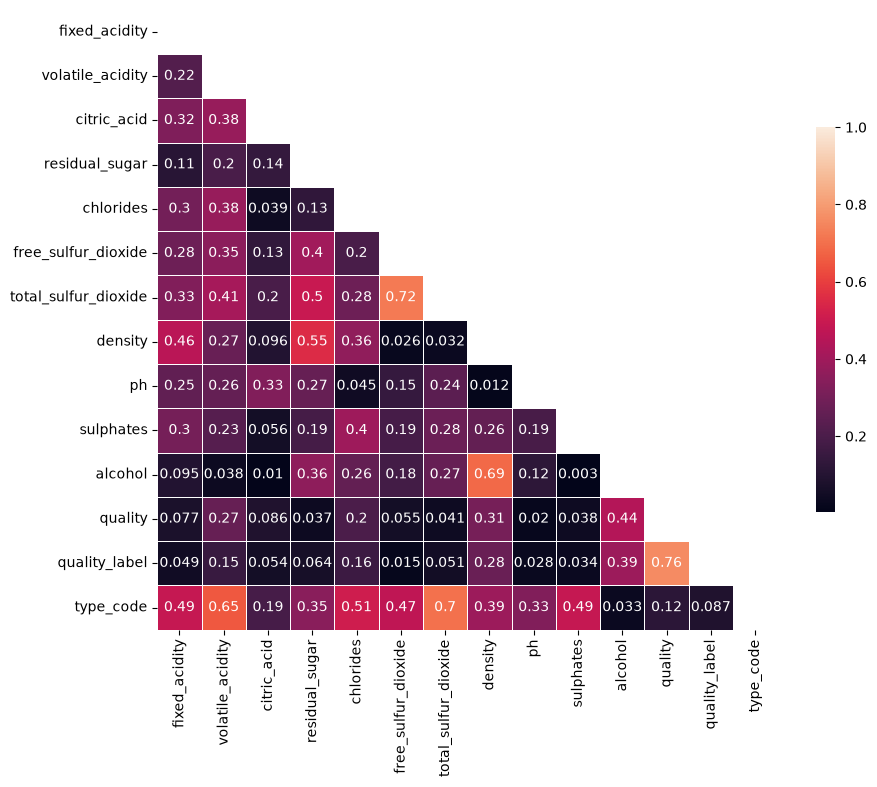

In [10]:
corr = np.abs(df_wine.corr(numeric_only=True))                                                                        
                                                                                                                                                                                                      
                                                                                                      
#Set up mask for triangle representation                                                              
                                                                                                      
                                                                                                      
mask = np.zeros_like(corr, dtype=bool)                                                                
                                                                                                      
                                                                                                      
mask[np.triu_indices_from(mask)] = True                                                                                                
                                                                                                      
                                                                                                      
# Set up the matplotlib figure                                                                        
                                                                                                      
                                                                                                      
f, ax = plt.subplots(figsize=(10, 10))                                                                
                                                                                                      
                                                                                                      
# Generate a custom diverging colormap                                                                
                                                                                                      
                                                                                                      
cmap = sns.diverging_palette(220, 10, as_cmap=True)                                                   
                                                                                                      
                                                                                                      
# Draw the heatmap with the mask and correct aspect ratio                                             
                                                                                                      
                                                                                                      
sns.heatmap(corr, mask=mask,  vmax=1,square=True, linewidths=.5, cbar_kws={"shrink": .5},annot = corr)
                                                                                                      
                                                                                                      
                                                                                                      
                                                                                                      
                                                                                                      
plt.show()                                                                                            